# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


# Теоретическая часть

## Постановка задачи

Лабораторная посвящена дообучению визуально-языковой модели Qwen2.5-VL-3B-Instruct на задаче визуального ответа на вопросы в формате множественного выбора. Модель получает изображение и текстовый вопрос с вариантами ответа, а на выходе должна выдать ровно одну букву — правильный вариант. Базовая модель уже умеет отвечать на вопросы про картинки, но делает это в свободной форме: может написать целое предложение, порассуждать, дать развёрнутый ответ. Для строгой метрики Exact Match, которая сравнивает ответ с эталоном посимвольно, такой формат не подходит. Задача лабораторной — научить модель отвечать одной буквой с помощью supervised fine-tuning, имея в распоряжении одну видеокарту T4 с 14.5 ГБ памяти.

## Суть supervised fine-tuning

Supervised fine-tuning — это обучение модели на парах «вход → правильный ответ». Модели показываются изображение, вопрос с вариантами и правильная буква, и она учится отвечать так же. Технически модель, как и при предобучении, предсказывает следующий токен, но есть принципиальная деталь: функция потерь считается только на токенах целевого ответа, а не на всём тексте промпта. Это отличает SFT от обычного предсказания следующего токена: модель учится именно отвечать, а не воспроизводить условие задачи. Если бы ошибка считалась на всём тексте, модель тренировалась бы повторять вопрос — очевидно, не то, что нужно. В используемом фреймворке это реализуется автоматически через шаблон чата: токены пользователя маскируются, обучаются только токены ассистента.

Важно понимать, что SFT на малой выборке учит модель прежде всего поведению — формату ответа, стилю, структуре, — а не добавляет ей новых знаний. Если базовая модель плохо знает материал, адаптер этот пробел не восполнит; он лишь заставит модель отвечать в нужном формате. Это ключевое ограничение метода, и оно напрямую влияет на интерпретацию результатов на разных срезах данных.

## Почему полный fine-tuning невозможен

Полный fine-tuning означает обновление всех весов модели. Для этого нужно хранить сами веса (около 7.5 ГБ в половинной точности для трёхмиллиардной модели), градиенты для каждого веса (ещё столько же) и состояние оптимизатора AdamW, которое обычно занимает вдвое больше, чем веса. Итого только на веса, градиенты и состояние оптимизатора уходит порядка 30 ГБ, плюс активации, которые при обучении тоже немаленькие. На видеокарте T4 с её 14.5 ГБ это принципиально невозможно. Поэтому используются два приёма, которые радикально сокращают требования к памяти: LoRA и квантизация. Вместе они образуют QLoRA — подход, позволяющий дообучать большие модели на маленьких видеокартах без существенной потери качества.

## LoRA: обучаем маленькую добавку вместо всей модели

Идея LoRA проста. У модели есть большие матрицы весов — например, размером 4096 на 4096. Мы их полностью замораживаем, не трогаем вообще. А рядом добавляем две маленькие матрицы, произведение которых даёт поправку к весам. Одна из них имеет размер 4096 на 8, другая — 8 на 4096, то есть вместо 16 миллионов параметров мы обучаем всего около 65 тысяч. В 250 раз меньше. При этом качество дообучения почти не страдает, потому что поправка, необходимая для адаптации модели к узкой задаче, действительно имеет низкий ранг — это эмпирически подтверждённое свойство нейросетей.

Размер этого внутреннего измерения называется рангом и определяет, насколько широкую поправку мы учим: больше ранг — больше выразительность адаптера, но и выше риск переобучения на малой выборке. Второй параметр задаёт масштаб поправки, и обычно его берут вдвое больше ранга, чтобы их отношение равнялось двум. В лабораторной используются стандартные значения: ранг 8 и масштаб 16. Отдельная тонкость: одна из двух маленьких матриц инициализируется нулями, поэтому в начале обучения поправка равна нулю и модель ведёт себя ровно как исходная. Обучение стартует плавно, без скачков, что важно для стабильности.

LoRA даёт сразу несколько выгод. Обучаемых параметров мало, поэтому градиенты и состояние оптимизатора занимают копейки. Обучение идёт быстрее, потому что обратный проход вычисляется только через маленькие матрицы. Сохранённый адаптер весит несколько мегабайт вместо гигабайт, и его легко подключать к разным копиям базовой модели. Но главная проблема — сами замороженные веса всё ещё занимают 7.5 ГБ — остаётся, и её решает квантизация.

## Квантизация: храним веса в 4 битах

QLoRA добавляет к LoRA второй приём: базовые веса хранятся в 4-битном формате вместо 16-битного. Это сжимает их в четыре раза, и модель занимает около 3 ГБ вместо 7.5. При вычислениях веса на лету распаковываются обратно в 16 бит, считается прямой и обратный проход, а хранятся всё равно в 4 битах. Формат сжатия специально оптимизирован под то, что веса нейросетей распределены примерно нормально, — это даёт меньше потерь точности, чем обычное 4-битное сжатие. Обучаемые LoRA-матрицы при этом остаются в полной точности, потому что их немного и экономить на них смысла нет.

В сумме QLoRA даёт около 3 ГБ на базовую модель плюс несколько мегабайт на адаптер плюс активации — всё это с запасом влезает в 14.5 ГБ T4. Но есть важное следствие, которое нужно понимать при работе с инференсом: адаптер нельзя влить обратно в 4-битную модель. Обычно после обучения LoRA-адаптер можно слить с базовыми весами — получается одна модель без накладных расходов. С квантованной базой это невозможно: нельзя влить точную поправку в сжатое представление без потери точности. Поэтому есть два режима работы. Либо адаптер подключается поверх квантованной базы без слияния — работает всегда, но чуть медленнее, потому что адаптер вычисляется на каждом проходе. Либо база загружается в полной точности, адаптер вливается, и получается обычная модель — быстрее, но требует больше памяти.

## LLaMA-Factory и гиперпараметры

Всё описанное можно было бы написать руками — обёртки над библиотеками, собственный тренировочный цикл. LLaMA-Factory делает это за вас и фиксирует всю конфигурацию в одном файле. Фреймворк берёт на себя шаблоны чата (у каждой модели свой формат диалога, свои специальные токены — фреймворк знает формат Qwen2.5-VL и подставляет его автоматически), форматы данных (список сообщений с ролями system, user и assistant; вы отдаёте данные в этом формате, фреймворк сам превращает их в тензоры), квантизацию и LoRA (один параметр — и модель грузится в 4-битном виде с адаптером), сохранение контрольных точек и логирование метрик. Главное преимущество — воспроизводимость: вся конфигурация в одном файле, и при одинаковых настройках и данных результаты должны совпасть с точностью до недетерминизма видеокарты.

В конфигурации лабораторной фиксируются ключевые параметры. Ранг адаптера, равный 8, задаёт его ёмкость — это консервативный выбор для малой выборки, поскольку больший ранг легче переобучается. Масштаб поправки 16 задаёт стандартное соотношение два к одному с рангом. Батч равен единице, а накопление градиентов — шестнадцати: физически на видеокарту влезает только один пример, но градиенты накапливаются с шестнадцати примеров, прежде чем обновить веса, что эффективно даёт обучение на батче из шестнадцати и стабилизирует градиент. Скорость обучения выбрана выше, чем при полном fine-tuning, потому что обучаемых параметров мало и можно позволить себе более агрессивные шаги. Число шагов — сто, что мало, но задача узкая: научить формату, а не знаниям. Валидация каждые двадцать шагов позволяет выбрать лучшую контрольную точку по метрике, а не по последнему шагу. При ста шагах и эффективном батче шестнадцать модель «увидит» около 1600 примеров, что при обучающей выборке в 512 составляет примерно три эпохи — достаточно, чтобы выучить формат ответа, но недостаточно, чтобы кардинально изменить знания модели.

## Метрика и срезы оценки

Метрика — точное совпадение по букве: предсказание считается верным, только если извлечённая из ответа буква совпадает с эталонной. Метрика намеренно жёсткая и не прощает ошибок формата: если модель написала «The answer is B», а извлечение буквы не сработало, это ошибка, а не «почти правильно». В знаменателе — все примеры соответствующего среза, включая те, где модель не смогла выдать валидную букву. Такая жёсткость оправдана: мы обучаем модель строгому формату, и если она его не соблюдает, это провал задачи, а не мелкая погрешность.

Оценка ведётся на трёх независимых срезах. Первый — in-distribution: естественные науки, классы с первого по шестой, то же распределение, что и в обучающей выборке; здесь улучшение ожидаемо, потому что модель видела похожие примеры. Второй — out-of-distribution: тот же предмет, но классы с седьмого по двенадцатый; вопросы сложнее, лексика другая, и здесь проверяется, обобщается ли выученный формат на более трудный материал. Третий — общий: другие предметы, история, география, обществознание; проверяется перенос на домены, которых в обучении не было вообще.

## Почему улучшение на ID не гарантирует улучшение на OOD

Это ключевой момент для интерпретации результатов. SFT на малой выборке учит модель поведению — как отвечать, в каком формате, каким стилем, — но не добавляет знаний. Если базовая модель плохо знает материал седьмых-двенадцатых классов, адаптер этот пробел не восполнит; он лишь заставит модель отвечать в нужном формате. Более того, возможен негативный перенос: адаптер, настроенный на короткие простые вопросы младших классов, может ухудшить рассуждения на сложных OOD-примерах, поскольку модель затачивается под поверхностные паттерны обучающего распределения и теряет гибкость на других. Именно поэтому сравнение базовой модели и адаптера на OOD — содержательная часть эксперимента, а не формальность. Если SFT улучшил ID, но ухудшил OOD, это важный результат, показывающий, что метод выучил формат, но не обобщил знания.

## Детерминированный инференс

Чтобы сравнение базовой модели и адаптера было честным, всё кроме весов модели должно быть одинаковым. Во-первых, отключается семплирование — используется жадное декодирование, при котором всегда выбирается самый вероятный токен. Если включить случайный выбор, каждая модель будет отвечать по-разному от запуска к запуску, и сравнение потеряет смысл. Во-вторых, одинаковым должен быть бюджет генерации: если у одной модели пять токенов, а у другой пятьдесят, метрика несопоставима. В-третьих, один и тот же процессор и шаблон чата — входные тензоры должны быть идентичны. В-четвёртых, из выхода декодируются только сгенерированные токены, без исходного промпта, иначе в ответ попадёт сам вопрос и метрика сломается. Всё это инкапсулируется в одну функцию предсказания, которая используется и для базовой модели, и для адаптера, — так гарантируется, что единственное различие между двумя прогонами это веса модели.

## Воспроизводимость и возобновление обучения

Есть два разных способа «продолжить обучение», и их важно не путать. Загрузка весов берёт только матрицы адаптера из контрольной точки; оптимизатор, планировщик скорости обучения и счётчик шагов сбрасываются. Это новый запуск с уже обученным адаптером, а не продолжение. Восстановление состояния берёт и веса, и состояние оптимизатора, и планировщик, и состояние генератора случайных чисел, и номер глобального шага; только так обучение продолжится так, как будто не прерывалось. Кроме того, «последнюю» контрольную точку нужно выбирать по числовому номеру шага, а не по алфавиту. Строка с номером сто лексикографически меньше, чем строка с номером двадцать, поскольку символ «1» меньше «2», и при выборе по алфавиту можно откатиться со сотого шага на двадцатый, потеряв большую часть прогресса.

## Ограничения протокола

В отчёте необходимо честно указать ограничения, иначе результаты будут интерпретированы неверно. Малая выборка — 512 обучающих примеров и по 64 на каждый тест — означает, что статистическая погрешность метрики при таком размере составляет около шести процентных пунктов; если адаптер показал 45%, а базовая модель 42%, это может быть шумом, а не реальным улучшением. Один запуск с одним зерном случайности не даёт оценки вариативности между запусками. OOD — это выбор границы, а не свойство данных: определение «естественные науки, классы 7–12» как OOD является операциональным решением, и другой исследователь мог бы провести границу иначе. Множественный выбор упрощает задачу: при четырёх вариантах модель может угадать с вероятностью 25%, и метрику нужно интерпретировать с учётом этого baseline. Наконец, перевес букв: если в данных буква «A» встречается в 40% примеров, модель, всегда отвечающая «А», получит 40% без какого-либо понимания задачи — поэтому в лабораторной предусмотрен визуальный аудит распределения букв по срезам.


### Математическая постановка

$$W'=W_q+\frac{\alpha}{r}BA,\quad B\in\mathbb R^{d\times r},\ A\in\mathbb R^{r\times k}.$$ Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

In [2]:
# ============================================================
# ЯЧЕЙКА 1. НАСТРОЙКА ОКРУЖЕНИЯ
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, os, random, subprocess, sys, hashlib, time
import numpy as np

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Полный режим (не smoke), но с ограничениями под T4
FAST_DEV_RUN = False

# Артефакты — на Drive (переживут отключение)
ARTIFACTS = Path('/content/drive/MyDrive/lab9_artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Данные и LLaMA-Factory — локально (быстрее, Drive медленный)
LOCAL_WORK = Path('/content/lab9_work')
LOCAL_WORK.mkdir(exist_ok=True)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device={DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

def check(cond, msg):
    print(("✔ " if cond else "✘ ВНИМАНИЕ: ") + msg)

def save_json(name, data):
    (ARTIFACTS / name).write_text(
        json.dumps(data, ensure_ascii=False, indent=2, default=str),
        encoding="utf-8")

def run_cmd(cmd, log_path=None, extra_env=None):
    """Запускает команду, пишет stdout+stderr в лог, возвращает код."""
    print(f"$ {' '.join(cmd)}")
    env = os.environ.copy()
    if extra_env:
        env.update(extra_env)
    try:
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE,
                                stderr=subprocess.STDOUT, text=True,
                                bufsize=1, env=env)
    except FileNotFoundError as e:
        msg = f"✘ Команда не найдена: {cmd[0]}\n  Причина: {e}\n"
        print(msg)
        if log_path is not None:
            Path(log_path).write_text(msg, encoding="utf-8")
        return 127
    lines = []
    for line in proc.stdout:
        print(line, end="")
        lines.append(line)
    proc.wait()
    if log_path is not None:
        Path(log_path).write_text("".join(lines), encoding="utf-8")
    return proc.returncode

Mounted at /content/drive
device=cuda
GPU: Tesla T4
VRAM: 15.6 GB


In [3]:
# ============================================================
# ЯЧЕЙКА 2. УСТАНОВКА СВЕЖЕГО LLAMA-FACTORY
# ============================================================
LLAMA_FACTORY_DIR = LOCAL_WORK / "LLaMA-Factory"

import shutil
if LLAMA_FACTORY_DIR.exists():
    print(f"Удаляю старую {LLAMA_FACTORY_DIR}...")
    shutil.rmtree(LLAMA_FACTORY_DIR)

print("Клонирую свежий LLaMA-Factory...")
r = subprocess.run(
    ["git", "clone", "--depth", "1",
     "https://github.com/hiyouga/LLaMA-Factory.git",
     str(LLAMA_FACTORY_DIR)],
    capture_output=True, text=True)
print("Код clone:", r.returncode, r.stderr[-500:])
check((LLAMA_FACTORY_DIR / "pyproject.toml").is_file(), "pyproject.toml на месте")

# Смотрим, что за версия
r = subprocess.run(["git", "-C", str(LLAMA_FACTORY_DIR), "log", "-1", "--oneline"],
                   capture_output=True, text=True)
print("Commit:", r.stdout.strip())

# Ставим в системный Python
print("\nУстанавливаю LLaMA-Factory (5-10 минут)...")
r = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e",
     f"{LLAMA_FACTORY_DIR}[torch,metrics]"],
    capture_output=True, text=True)
print("Код установки:", r.returncode)
print("STDOUT (последние 1000):", r.stdout[-1000:])
if r.returncode != 0:
    print("STDERR (последние 3000):", r.stderr[-3000:])

Клонирую свежий LLaMA-Factory...
Код clone: 0 Cloning into '/content/lab9_work/LLaMA-Factory'...

✔ pyproject.toml на месте
Commit: 1fded91 [docs] add security notes to NPU Docker overviews (#10883)

Устанавливаю LLaMA-Factory (5-10 минут)...
Код установки: 0
STDOUT (последние 1000): transformers-5.18.0:
      Successfully uninstalled transformers-5.18.0
  Attempting uninstall: gradio
    Found existing installation: gradio 6.29.0
    Uninstalling gradio-6.29.0:
      Successfully uninstalled gradio-6.29.0
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.15.0
    Uninstalling accelerate-1.15.0:
      Successfully uninstalled accelerate-1.15.0
  Attempting uninstall: peft
    Found existing installation: peft 0.21.1
    Uninstalling peft-0.21.1:
      Successfully uninstalled peft-0.21.1



In [4]:
# ============================================================
# ЯЧЕЙКА 3. ПРОВЕРКА УСТАНОВКИ
# ============================================================
import importlib, shutil
importlib.invalidate_caches()

cli_path = shutil.which("llamafactory-cli")
print("llamafactory-cli в PATH:", cli_path)

try:
    import llamafactory
    print("✔ llamafactory:", llamafactory.__file__)
    llamafactory_ok = True
except Exception as e:
    print("✘ Импорт упал:", e)
    llamafactory_ok = False

if cli_path:
    LLAMAFACTORY_CMD = [cli_path]
elif llamafactory_ok:
    LLAMAFACTORY_CMD = [sys.executable, "-m", "llamafactory.cli"]
else:
    raise RuntimeError("LLaMA-Factory не установлен")

print("LLAMAFACTORY_CMD:", LLAMAFACTORY_CMD)

# Проверка версии
r = subprocess.run(LLAMAFACTORY_CMD + ["version"], capture_output=True, text=True)
print("version:", r.stdout.strip(), r.stderr[-300:] if r.returncode != 0 else "")

llamafactory-cli в PATH: /usr/local/bin/llamafactory-cli
✘ Импорт упал: No module named 'llamafactory'
LLAMAFACTORY_CMD: ['/usr/local/bin/llamafactory-cli']
version: ----------------------------------------------------------
| Welcome to LLaMA Factory, version 0.9.6.dev0           |
|                                                        |
| Project page: https://github.com/hiyouga/LLaMA-Factory |
---------------------------------------------------------- 


### Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


In [5]:
# ============================================================
# ЯЧЕЙКА 4. ЗАДАНИЕ 1: МАНИФЕСТ
# ============================================================
from datasets import load_dataset

SCIENCEQA_ID = "derek-thomas/ScienceQA"
SCIENCEQA_REVISION = "f18b0a70359ebfb41f658fd564208d0355b013f4"
DATA_DIR = LOCAL_WORK / "lab9"

def prepare_scienceqa(directory, smoke=False):
    directory = Path(directory).resolve()
    directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ("manifest-smoke.jsonl" if smoke else "manifest.jsonl")

    limits = ({"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4}
              if smoke else
              {"train": 512, "validation": 64, "id_test": 64, "ood_test": 64, "general_test": 64})

    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text(encoding="utf-8").splitlines() if s.strip()]
        if (all(Path(r["image"]).is_file() for r in records)
                and all(sum(r["split"] == s for r in records) == n for s, n in limits.items())):
            print(f"✔ Манифест готов: {manifest}")
            return manifest

    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ("train", "validation", "test"):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION,
                            split=official, streaming=True)
        for index, row in enumerate(data):
            image = row["image"]
            if image is None:
                continue
            if official != "test":
                if row["subject"] != "natural science":
                    continue
                if int(row["grade"].removeprefix("grade")) > 6:
                    continue
                split = official
            else:
                if row["subject"] != "natural science":
                    split = "general_test"
                elif int(row["grade"].removeprefix("grade")) > 6:
                    split = "ood_test"
                else:
                    split = "id_test"
            if counts[split] >= limits[split]:
                continue
            image = image.convert("RGB")
            digest = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
            if digest in seen:
                continue
            seen.add(digest)
            path = directory / f"{digest}.png"
            image.save(path)
            answer = int(row["answer"])
            choices = row["choices"]
            question = (row["question"] + "\n"
                        + "\n".join(f"{chr(65+i)}. {v}" for i, v in enumerate(choices))
                        + "\nReturn only the letter of the correct option.")
            records.append({
                "id": f"scienceqa-{official}-{index}",
                "split": split, "image": str(path),
                "question": question, "answer": chr(65 + answer),
                "choices": choices, "answer_index": answer,
                "label_type": "multiple_choice",
                "license": "CC-BY-SA-4.0",
                "source_url": f"https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}",
                "subject": row["subject"], "grade": row["grade"],
                "image_sha256": digest,
            })
            counts[split] += 1
            required = ([official] if official != "test"
                        else ["id_test", "ood_test", "general_test"])
            if all(counts[s] == limits[s] for s in required):
                break
    if counts != limits:
        raise RuntimeError(f"Не хватило: {counts}; ожидали {limits}")
    manifest.write_text("\n".join(json.dumps(r, ensure_ascii=False) for r in records) + "\n",
                        encoding="utf-8")
    (directory / "ATTRIBUTION.md").write_text(
        "ScienceQA — Lu et al., NeurIPS 2022.\n"
        f"Dataset: {SCIENCEQA_ID}\nRevision: {SCIENCEQA_REVISION}\n"
        "License: CC-BY-SA-4.0\n"
        "ID: natural science 1-6 | OOD: natural science 7-12 | General: other subjects\n",
        encoding="utf-8")
    return manifest

manifest_path = prepare_scienceqa(DATA_DIR, smoke=FAST_DEV_RUN)
records = [json.loads(l) for l in manifest_path.read_text(encoding="utf-8").splitlines() if l.strip()]

from collections import Counter
split_counts = Counter(r["split"] for r in records)
expected = ({"train": 8, "validation": 4, "id_test": 4, "ood_test": 4, "general_test": 4}
            if FAST_DEV_RUN else
            {"train": 512, "validation": 64, "id_test": 64, "ood_test": 64, "general_test": 64})
check(dict(split_counts) == expected, f"Сплиты: {dict(split_counts)}")

by_split = {}
for r in records:
    by_split.setdefault(r["split"], set()).add(r["image_sha256"])
sl = list(by_split.keys())
overlap = any(by_split[sl[i]] & by_split[sl[j]]
              for i in range(len(sl)) for j in range(i + 1, len(sl)))
check(not overlap, "Пересечений по хешу нет")
check(all(Path(r["image"]).is_file() for r in records), "Все картинки на диске")

README.md:   0%|          | 0.00/10.3k [00:00<?, ?B/s]

✔ Сплиты: {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}
✔ Пересечений по хешу нет
✔ Все картинки на диске


### Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


Распределение ответов по split'ам:
  general_test: {'A': 13, 'B': 21, 'C': 17, 'D': 13, 'E': 0}
  id_test: {'A': 26, 'B': 27, 'C': 11, 'D': 0, 'E': 0}
  ood_test: {'A': 25, 'B': 27, 'C': 9, 'D': 3, 'E': 0}
  train: {'A': 209, 'B': 230, 'C': 72, 'D': 1, 'E': 0}
  validation: {'A': 24, 'B': 32, 'C': 8, 'D': 0, 'E': 0}


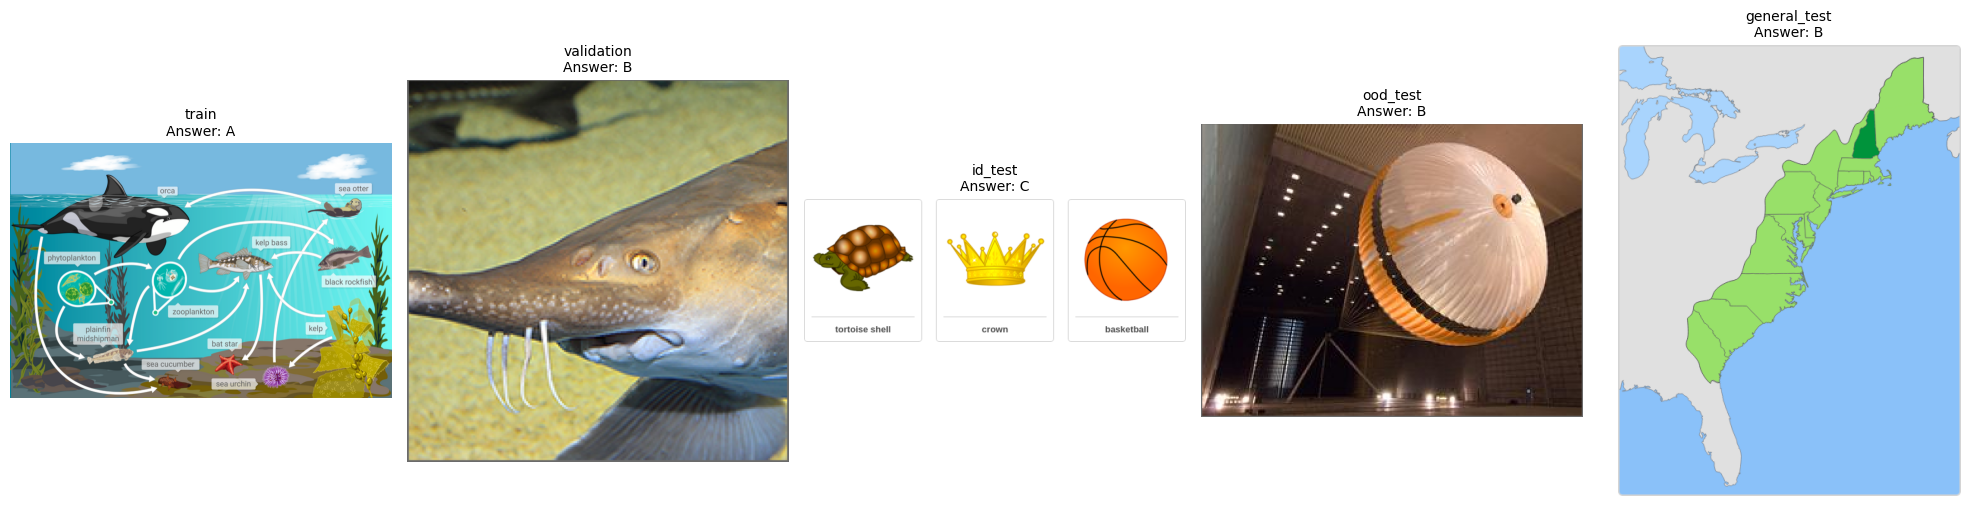

✔ Сохранено: /content/drive/MyDrive/lab9_artifacts/data_preview.png


In [6]:
# ============================================================
# ЯЧЕЙКА 5. ЗАДАНИЕ 2: ВИЗУАЛЬНЫЙ АУДИТ
# ============================================================
import matplotlib.pyplot as plt
from PIL import Image

answer_dist = {}
for split in sorted(set(r["split"] for r in records)):
    subset = [r for r in records if r["split"] == split]
    dist = Counter(r["answer"] for r in subset)
    answer_dist[split] = {k: dist.get(k, 0) for k in "ABCDE"}
save_json("data_profile.json", {
    "n_per_split": dict(split_counts),
    "answer_distribution": answer_dist,
    "source": SCIENCEQA_ID, "revision": SCIENCEQA_REVISION,
})
print("Распределение ответов по split'ам:")
for split, dist in answer_dist.items():
    print(f"  {split}: {dist}")

splits_ordered = ["train", "validation", "id_test", "ood_test", "general_test"]
fig, axes = plt.subplots(1, len(splits_ordered), figsize=(20, 5))
for ax, split in zip(axes, splits_ordered):
    subset = [r for r in records if r["split"] == split]
    if not subset:
        ax.axis("off"); continue
    r = subset[0]
    ax.imshow(Image.open(r["image"]).convert("RGB"))
    ax.axis("off")
    ax.set_title(f"{split}\nAnswer: {r['answer']}", fontsize=10)
plt.tight_layout()
plt.savefig(ARTIFACTS / "data_preview.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'data_preview.png'}")

РАСПРЕДЕЛЕНИЕ ПРАВИЛЬНЫХ ОТВЕТОВ ПО РАЗБИЕНИЯМ

general_test (n=64):
  A:  13 ( 20.3%) ████
  B:  21 ( 32.8%) ██████
  C:  17 ( 26.6%) █████
  D:  13 ( 20.3%) ████
  E:   0 (  0.0%) 

id_test (n=64):
  A:  26 ( 40.6%) ████████
  B:  27 ( 42.2%) ████████
  C:  11 ( 17.2%) ███
  D:   0 (  0.0%) 
  E:   0 (  0.0%) 

ood_test (n=64):
  A:  25 ( 39.1%) ███████
  B:  27 ( 42.2%) ████████
  C:   9 ( 14.1%) ██
  D:   3 (  4.7%) 
  E:   0 (  0.0%) 

train (n=512):
  A: 209 ( 40.8%) ████████
  B: 230 ( 44.9%) ████████
  C:  72 ( 14.1%) ██
  D:   1 (  0.2%) 
  E:   0 (  0.0%) 

validation (n=64):
  A:  24 ( 37.5%) ███████
  B:  32 ( 50.0%) ██████████
  C:   8 ( 12.5%) ██
  D:   0 (  0.0%) 
  E:   0 (  0.0%) 


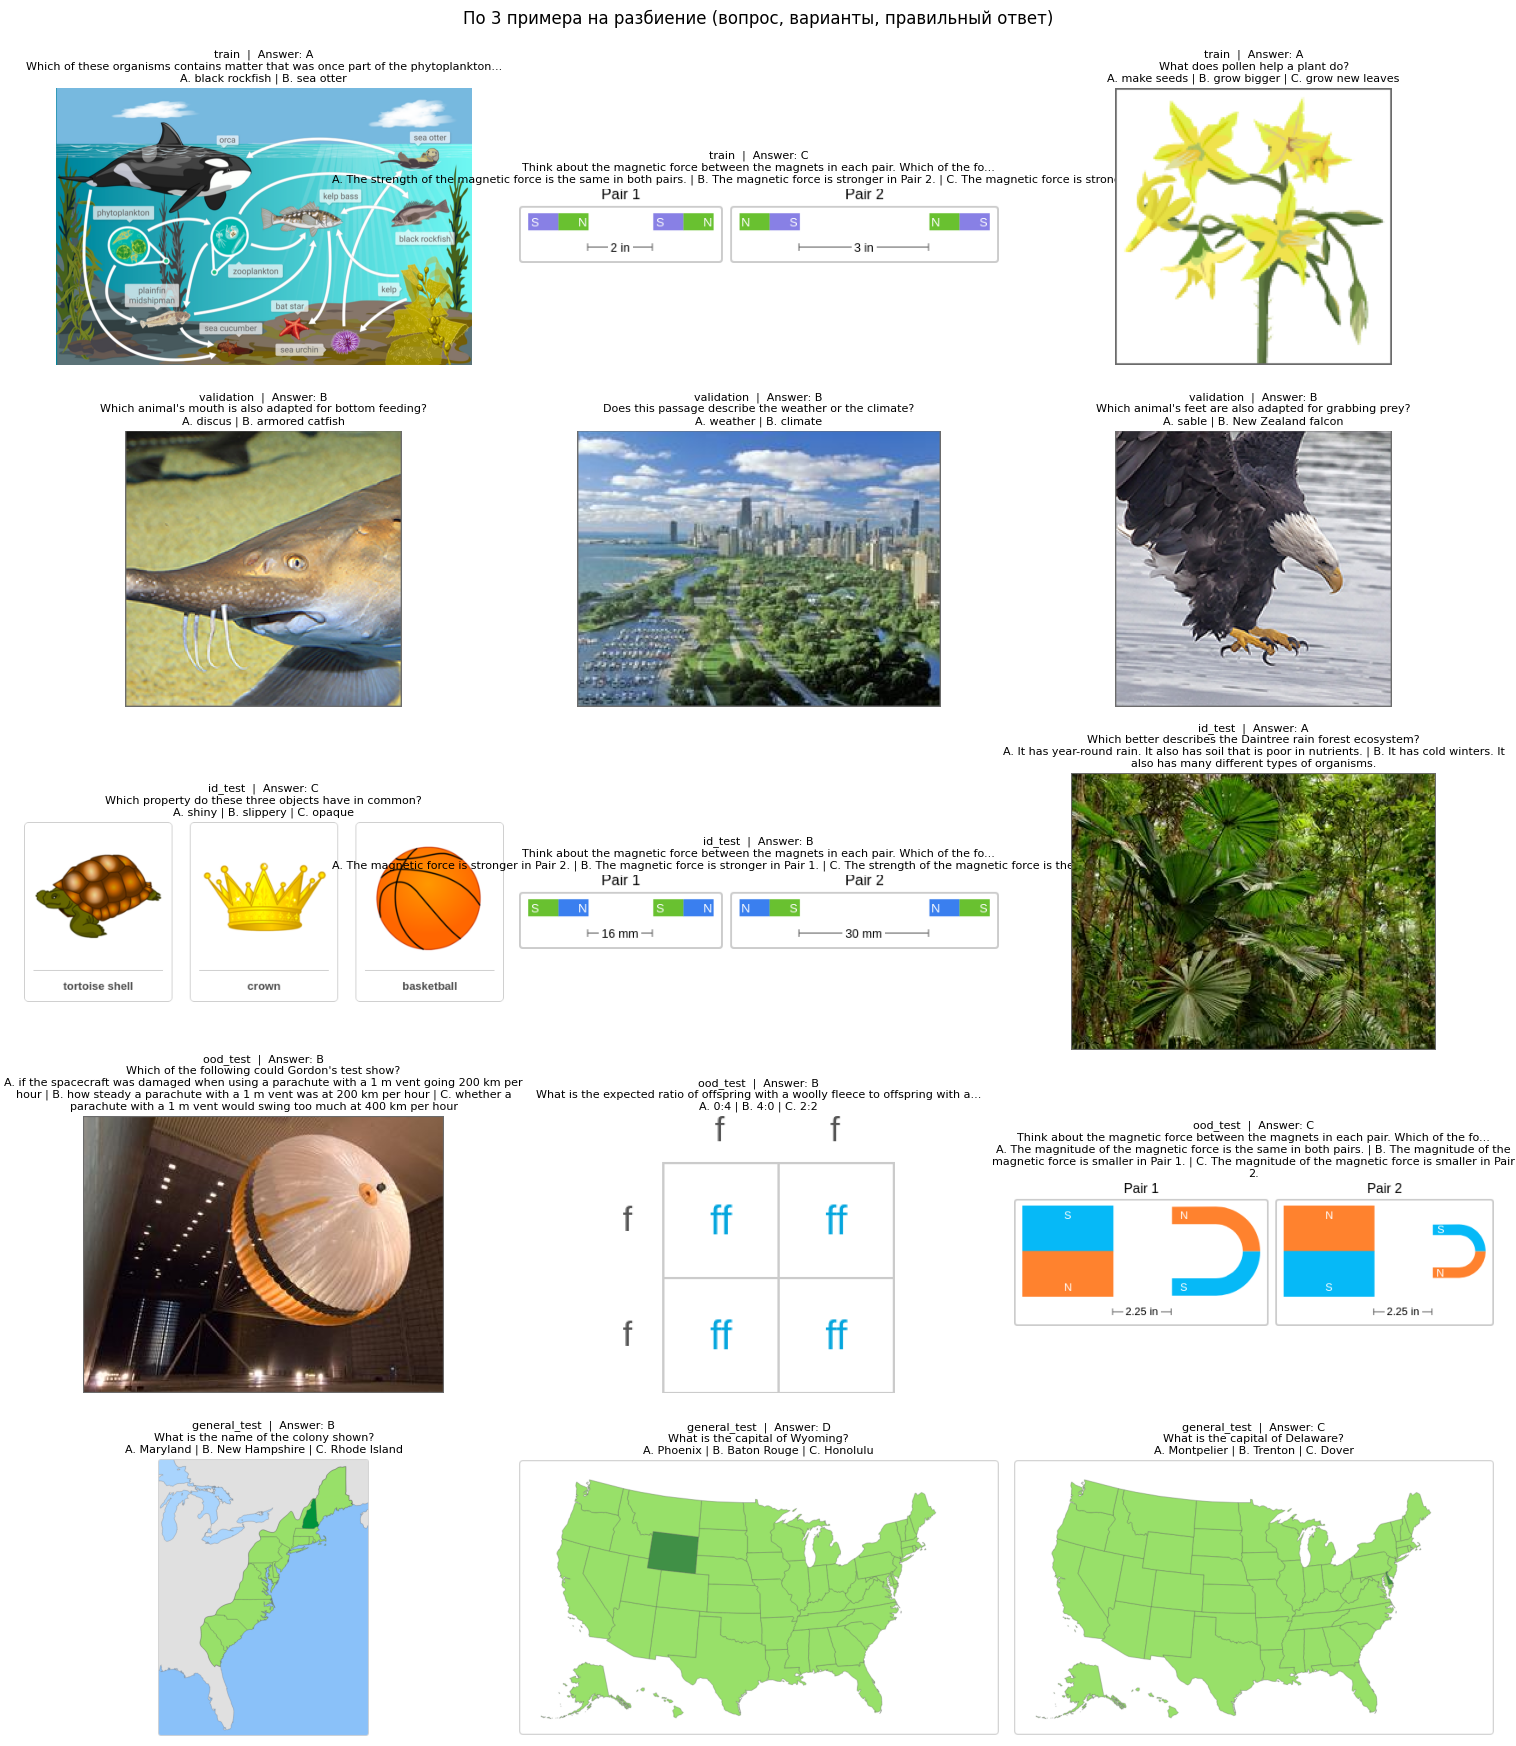


✔ Сохранено: /content/drive/MyDrive/lab9_artifacts/data_preview.png


In [13]:
# ============================================================
# ЯЧЕЙКА 5 (УЛУЧШЕННАЯ). ВИЗУАЛЬНЫЙ АУДИТ
# ============================================================
import matplotlib.pyplot as plt
from PIL import Image

# 1. Распределение ответов
answer_dist = {}
for split in sorted(set(r["split"] for r in records)):
    subset = [r for r in records if r["split"] == split]
    dist = Counter(r["answer"] for r in subset)
    answer_dist[split] = {k: dist.get(k, 0) for k in "ABCDE"}
save_json("data_profile.json", {
    "n_per_split": dict(split_counts),
    "answer_distribution": answer_dist,
    "source": SCIENCEQA_ID, "revision": SCIENCEQA_REVISION,
})

print("=" * 70)
print("РАСПРЕДЕЛЕНИЕ ПРАВИЛЬНЫХ ОТВЕТОВ ПО РАЗБИЕНИЯМ")
print("=" * 70)
for split, dist in answer_dist.items():
    total = sum(dist.values())
    print(f"\n{split} (n={total}):")
    for letter in "ABCDE":
        cnt = dist[letter]
        pct = 100 * cnt / total if total else 0
        bar = "█" * int(pct / 5)
        print(f"  {letter}: {cnt:3d} ({pct:5.1f}%) {bar}")

# 2. Сетка: по 3 примера на split, с вопросом и вариантами
splits_ordered = ["train", "validation", "id_test", "ood_test", "general_test"]
N_PER_SPLIT = 3

fig, axes = plt.subplots(len(splits_ordered), N_PER_SPLIT,
                         figsize=(15, 3.5 * len(splits_ordered)))
for row, split in enumerate(splits_ordered):
    subset = [r for r in records if r["split"] == split]
    for col in range(N_PER_SPLIT):
        ax = axes[row, col]
        if col >= len(subset):
            ax.axis("off")
            continue
        r = subset[col]
        ax.imshow(Image.open(r["image"]).convert("RGB"))
        ax.axis("off")
        # Обрезаем вопрос до 80 символов, чтобы влез
        q = r["question"].split("\n")[0]
        q_short = q[:80] + "..." if len(q) > 80 else q
        # Варианты
        choices = r["question"].split("\n")[1:-1]  # без первой строки и последней
        choices_str = " | ".join(choices[:3])
        title = f"{split}  |  Answer: {r['answer']}\n{q_short}\n{choices_str}"
        ax.set_title(title, fontsize=8, wrap=True)

plt.suptitle("По 3 примера на разбиение (вопрос, варианты, правильный ответ)",
             fontsize=12, y=0.995)
plt.tight_layout()
plt.savefig(ARTIFACTS / "data_preview.png", dpi=110, bbox_inches="tight")
plt.show()
print(f"\n✔ Сохранено: {ARTIFACTS / 'data_preview.png'}")

### Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


In [7]:
# ============================================================
# ЯЧЕЙКА 6. ЗАДАНИЕ 3: ЭКСПОРТ В SHAREGPT
# ============================================================
DATA_EXPORT_DIR = LLAMA_FACTORY_DIR / "data" / "lab9"
DATA_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def to_sharegpt(rec):
    return {
        "id": rec["id"],
        "conversations": [
            {"from": "human", "value": "<image>\n" + rec["question"]},
            {"from": "gpt", "value": rec["answer"]},
        ],
        "image": rec["image"],
        "answer_index": rec["answer_index"],
    }

train_recs = [r for r in records if r["split"] == "train"]
val_recs = [r for r in records if r["split"] == "validation"]
train_json = [to_sharegpt(r) for r in train_recs]
val_json = [to_sharegpt(r) for r in val_recs]

(DATA_EXPORT_DIR / "train.json").write_text(
    json.dumps(train_json, ensure_ascii=False, indent=2), encoding="utf-8")
(DATA_EXPORT_DIR / "validation.json").write_text(
    json.dumps(val_json, ensure_ascii=False, indent=2), encoding="utf-8")

dataset_info = {
    "lab9_train": {
        "file_name": "train.json", "formatting": "sharegpt",
        "columns": {"messages": "conversations", "images": "image"},
        "tags": {"role_tag": "from", "content_tag": "value",
                 "user_tag": "human", "assistant_tag": "gpt"},
    },
    "lab9_validation": {
        "file_name": "validation.json", "formatting": "sharegpt",
        "columns": {"messages": "conversations", "images": "image"},
        "tags": {"role_tag": "from", "content_tag": "value",
                 "user_tag": "human", "assistant_tag": "gpt"},
    },
}
(DATA_EXPORT_DIR / "dataset_info.json").write_text(
    json.dumps(dataset_info, ensure_ascii=False, indent=2), encoding="utf-8")

check(len(train_json) > 0, f"train.json: {len(train_json)}")
check(len(val_json) > 0, f"validation.json: {len(val_json)}")
check(all(Path(ex["image"]).is_file() for ex in train_json + val_json),
      "Все пути разрешаются")
print(f"✔ Экспортировано в {DATA_EXPORT_DIR}")

✔ train.json: 512
✔ validation.json: 64
✔ Все пути разрешаются
✔ Экспортировано в /content/lab9_work/LLaMA-Factory/data/lab9


### Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


In [8]:
# ============================================================
# ЯЧЕЙКА 7. ЗАДАНИЕ 4: YAML ПОД T4
# ============================================================
import yaml

OUTPUT_DIR = (ARTIFACTS / "lab9_adapter").resolve()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_STEPS = 60
EVAL_STEPS = 20
SAVE_STEPS = 20
CUTOFF_LEN = 768
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

sft_config = {
    "model_name_or_path": MODEL_ID,
    "trust_remote_code": True,
    "flash_attn": "fa2",

    "stage": "sft",
    "do_train": True,
    "do_eval": True,
    "dataset": "lab9_train",
    "eval_dataset": "lab9_validation",
    "dataset_dir": str(DATA_EXPORT_DIR.resolve()),
    "template": "qwen2_vl",
    "cutoff_len": CUTOFF_LEN,

    "quantization_bit": 4,
    "quantization_type": "nf4",
    "double_quantization": True,
    "lora_rank": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "lora_target": "all",

    "per_device_train_batch_size": 1,
    "per_device_eval_batch_size": 1,
    "gradient_accumulation_steps": 16,
    "learning_rate": 1e-4,
    "lr_scheduler_type": "cosine",
    "warmup_ratio": 0.1,
    "num_train_epochs": 1.0,
    "max_steps": MAX_STEPS,

    "eval_strategy": "steps",
    "eval_steps": EVAL_STEPS,
    "save_strategy": "steps",
    "save_steps": SAVE_STEPS,
    "save_total_limit": 2,
    "load_best_model_at_end": True,
    "metric_for_best_model": "eval_loss",

    "output_dir": str(OUTPUT_DIR),
    "logging_steps": 1,
    "report_to": "none",
    "overwrite_output_dir": False,
    "resume_from_checkpoint": None,

    "bf16": False,
    "fp16": True,
    "gradient_checkpointing": True,
    "ddp_timeout": 180000000,
}

yaml_path = ARTIFACTS / "sft.yaml"
yaml_path.write_text(yaml.safe_dump(sft_config, allow_unicode=True), encoding="utf-8")
check(yaml_path.is_file(), f"sft.yaml записан: {yaml_path}")

✔ sft.yaml записан: /content/drive/MyDrive/lab9_artifacts/sft.yaml


### Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


In [9]:
# ============================================================
# ЯЧЕЙКА 8. ЗАДАНИЕ 5: RESUME
# ============================================================
import re

def find_latest_checkpoint(output_dir):
    output_dir = Path(output_dir)
    if not output_dir.exists():
        return None
    candidates = []
    for p in output_dir.iterdir():
        if not p.is_dir():
            continue
        m = re.fullmatch(r"checkpoint-(\d+)", p.name)
        if m is None:
            continue
        if not (p / "trainer_state.json").is_file():
            continue
        candidates.append((int(m.group(1)), p))
    if not candidates:
        return None
    candidates.sort(key=lambda t: t[0])
    return candidates[-1][1]

latest_ckpt = find_latest_checkpoint(OUTPUT_DIR)
resume_protocol = {
    "output_dir": str(OUTPUT_DIR),
    "checkpoint_found": latest_ckpt is not None,
    "checkpoint_path": str(latest_ckpt) if latest_ckpt else None,
    "resume_mode": "resume" if latest_ckpt else "new_run",
}
sft_config["resume_from_checkpoint"] = str(latest_ckpt) if latest_ckpt else None
yaml_path.write_text(yaml.safe_dump(sft_config, allow_unicode=True), encoding="utf-8")
save_json("resume_protocol.json", resume_protocol)
check(True, f"Режим: {resume_protocol['resume_mode']}, checkpoint={latest_ckpt}")

✔ Режим: new_run, checkpoint=None


### Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


In [11]:
! pip install bitsandbytes

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 29.1 MB/s eta 0:00:00


In [12]:
# ============================================================
# ЯЧЕЙКА 9. ЗАДАНИЕ 6: ОБУЧЕНИЕ
# ============================================================
train_log = ARTIFACTS / "train.log"
train_cmd = LLAMAFACTORY_CMD + ["train", str(yaml_path.resolve())]
print(f"Команда: {' '.join(train_cmd)}")

exit_code = run_cmd(
    train_cmd,
    log_path=train_log,
    extra_env={"MPLBACKEND": "agg"},
)
check(exit_code == 0, f"llamafactory-cli код {exit_code}")

adapters = list(OUTPUT_DIR.rglob("adapter_model.safetensors"))
trainer_states = list(OUTPUT_DIR.rglob("trainer_state.json"))
check(len(adapters) > 0, f"adapter_model.safetensors: {adapters[:2]}")
check(len(trainer_states) > 0, f"trainer_state.json: {trainer_states[:2]}")

if trainer_states:
    state = json.loads(Path(trainer_states[0]).read_text())
    actual_steps = state.get("global_step")
    check(actual_steps == MAX_STEPS, f"Шагов: {actual_steps} (ожидали {MAX_STEPS})")

Команда: /usr/local/bin/llamafactory-cli train /content/drive/MyDrive/lab9_artifacts/sft.yaml
$ /usr/local/bin/llamafactory-cli train /content/drive/MyDrive/lab9_artifacts/sft.yaml
/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
[WARNING|2026-10-18 08:31:07] llamafactory.hparams.parser:149 >> We recommend enable `upcast_layernorm` in quantized training.
[INFO|2026-10-18 08:31:07] llamafactory.hparams.parser:651 >> Process rank: 0, world size: 1, device: cuda:0, distributed training: False, compute dtype: torch.float16
[INFO|configuration_utils.py:780] 2026-10-18 08:31:08,049 >> loading configuration file config.json

### Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


In [3]:
# ============================================================
# ВОССТАНОВЛЕНИЕ ПЕРЕМЕННЫХ ПОСЛЕ РЕСТАРТА
# ============================================================
from pathlib import Path
import json, random, subprocess, sys, os
import numpy as np
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

ARTIFACTS = Path('/content/drive/MyDrive/lab9_artifacts')
LOCAL_WORK = Path('/content/lab9_work')
DATA_DIR = LOCAL_WORK / "lab9"
LLAMA_FACTORY_DIR = LOCAL_WORK / "LLaMA-Factory"
DATA_EXPORT_DIR = LLAMA_FACTORY_DIR / "data" / "lab9"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device={DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

def check(cond, msg):
    print(("✔ " if cond else "✘ ВНИМАНИЕ: ") + msg)

def save_json(name, data):
    (ARTIFACTS / name).write_text(
        json.dumps(data, ensure_ascii=False, indent=2, default=str),
        encoding="utf-8")

def run_cmd(cmd, log_path=None, extra_env=None):
    print(f"$ {' '.join(cmd)}")
    env = os.environ.copy()
    if extra_env:
        env.update(extra_env)
    try:
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE,
                                stderr=subprocess.STDOUT, text=True,
                                bufsize=1, env=env)
    except FileNotFoundError as e:
        msg = f"✘ Команда не найдена: {cmd[0]}\n  Причина: {e}\n"
        print(msg)
        if log_path is not None:
            Path(log_path).write_text(msg, encoding="utf-8")
        return 127
    lines = []
    for line in proc.stdout:
        print(line, end="")
        lines.append(line)
    proc.wait()
    if log_path is not None:
        Path(log_path).write_text("".join(lines), encoding="utf-8")
    return proc.returncode

manifest_path = DATA_DIR / "manifest.jsonl"
records = [json.loads(l) for l in manifest_path.read_text(encoding="utf-8").splitlines() if l.strip()]
from collections import Counter
split_counts = Counter(r["split"] for r in records)
print(f"Записей: {len(records)} | {dict(split_counts)}")

MAX_STEPS = 60
OUTPUT_DIR = (ARTIFACTS / "lab9_adapter").resolve()
yaml_path = ARTIFACTS / "sft.yaml"
MODEL_ID = "Qwen/Qwen2.5-VL-3B-Instruct"

import shutil
cli = shutil.which("llamafactory-cli")
LLAMAFACTORY_CMD = [cli] if cli else [sys.executable, "-m", "llamafactory.cli"]
print("LLAMAFACTORY_CMD:", LLAMAFACTORY_CMD)

adapters = list(OUTPUT_DIR.rglob("adapter_model.safetensors"))
print("Адаптеры:", adapters if adapters else "нет")

# Освобождаем память
import gc
gc.collect()
torch.cuda.empty_cache()
print(f"VRAM после очистки: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
print("✔ Переменные восстановлены")

device=cuda
GPU: Tesla T4
VRAM: 15.6 GB
Записей: 768 | {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}
LLAMAFACTORY_CMD: ['/usr/local/bin/llamafactory-cli']
Адаптеры: [PosixPath('/content/drive/MyDrive/lab9_artifacts/lab9_adapter/adapter_model.safetensors'), PosixPath('/content/drive/MyDrive/lab9_artifacts/lab9_adapter/checkpoint-40/adapter_model.safetensors'), PosixPath('/content/drive/MyDrive/lab9_artifacts/lab9_adapter/checkpoint-60/adapter_model.safetensors')]
VRAM после очистки: 0.00 GB
✔ Переменные восстановлены


In [4]:
# ============================================================
# ЯЧЕЙКА 10. ЗАДАНИЕ 7: PREDICT (ИСПРАВЛЕНО под Qwen2.5-VL)
# ============================================================
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from PIL import Image

processor = AutoProcessor.from_pretrained(MODEL_ID, trust_remote_code=True)

# ВАЖНО: Qwen2_5_VLForConditionalGeneration, а не Qwen2VLForConditionalGeneration
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    trust_remote_code=True,
).to(DEVICE).eval()

MAX_NEW_TOKENS = 8

@torch.no_grad()
def predict(model, processor, image_path, question, max_new_tokens=MAX_NEW_TOKENS):
    img = Image.open(image_path).convert("RGB")
    messages = [{"role": "user", "content": [
        {"type": "image"}, {"type": "text", "text": question},
    ]}]
    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=[prompt], images=[img], return_tensors="pt")
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    input_len = inputs["input_ids"].shape[1]
    out = model.generate(**inputs, max_new_tokens=max_new_tokens,
                         do_sample=False, num_beams=1)
    return processor.batch_decode(out[:, input_len:], skip_special_tokens=True)[0].strip()

sample = [r for r in records if r["split"] == "id_test"][0]
sample_pred = predict(base_model, processor, sample["image"], sample["question"])
print(f"Пример: ответ={sample['answer']}, предсказание={sample_pred!r}")
check(sample["question"] not in sample_pred, "Ответ не содержит вопрос")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Пример: ответ=C, предсказание='C'
✔ Ответ не содержит вопрос


### Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


In [5]:
# ============================================================
# ЯЧЕЙКА 11. ЗАДАНИЕ 8: BASE PREDICTIONS
# ============================================================
test_recs = [r for r in records if r["split"] in ("id_test", "ood_test", "general_test")]
base_preds = []
for i, r in enumerate(test_recs):
    pred = predict(base_model, processor, r["image"], r["question"])
    base_preds.append({"id": r["id"], "split": r["split"],
                       "reference": r["answer"], "prediction_base": pred})
    if (i + 1) % 20 == 0:
        print(f"  base: {i+1}/{len(test_recs)}")

with (ARTIFACTS / "base_predictions.jsonl").open("w", encoding="utf-8") as f:
    for p in base_preds:
        f.write(json.dumps(p, ensure_ascii=False) + "\n")

check(len(base_preds) == len(test_recs), f"base: {len(base_preds)}")
check(len(set(p["id"] for p in base_preds)) == len(base_preds), "id уникальны")

  base: 20/192
  base: 40/192
  base: 60/192
  base: 80/192
  base: 100/192
  base: 120/192
  base: 140/192
  base: 160/192
  base: 180/192
✔ base: 192
✔ id уникальны


### Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


In [6]:
# ============================================================
# ЯЧЕЙКА 12. ЗАДАНИЕ 9: SFT PREDICTIONS
# ============================================================
from peft import PeftModel

adapter_path = OUTPUT_DIR
if not (adapter_path / "adapter_config.json").is_file():
    candidates = sorted(
        [p for p in OUTPUT_DIR.iterdir()
         if p.is_dir() and (p / "adapter_config.json").is_file()],
        key=lambda p: int(re.search(r"checkpoint-(\d+)", p.name).group(1)))
    adapter_path = candidates[-1] if candidates else None
check(adapter_path is not None, f"Адаптер: {adapter_path}")

sft_model = PeftModel.from_pretrained(base_model, str(adapter_path)).to(DEVICE).eval()

sft_preds = []
for i, r in enumerate(test_recs):
    pred = predict(sft_model, processor, r["image"], r["question"])
    sft_preds.append({"id": r["id"], "split": r["split"],
                      "reference": r["answer"], "prediction_sft": pred})
    if (i + 1) % 20 == 0:
        print(f"  sft: {i+1}/{len(test_recs)}")

base_by_id = {p["id"]: p for p in base_preds}
merged = [{"id": sp["id"], "split": sp["split"], "reference": sp["reference"],
           "prediction_base": base_by_id[sp["id"]]["prediction_base"],
           "prediction_sft": sp["prediction_sft"]} for sp in sft_preds]

with (ARTIFACTS / "predictions.jsonl").open("w", encoding="utf-8") as f:
    for m in merged:
        f.write(json.dumps(m, ensure_ascii=False) + "\n")

check(len(merged) == len(test_recs), f"Парных: {len(merged)}")
check(all(m["prediction_base"] and m["prediction_sft"] for m in merged),
      "У каждой пары оба предсказания")

✔ Адаптер: /content/drive/MyDrive/lab9_artifacts/lab9_adapter
  sft: 20/192
  sft: 40/192
  sft: 60/192
  sft: 80/192
  sft: 100/192
  sft: 120/192
  sft: 140/192
  sft: 160/192
  sft: 180/192
✔ Парных: 192
✔ У каждой пары оба предсказания


### Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


In [7]:
# ============================================================
# ЯЧЕЙКА 13. ЗАДАНИЕ 10: КАЧЕСТВО
# ============================================================
def exact_match(pred, ref):
    if not pred:
        return False
    return pred.strip().upper()[:1] == ref.strip().upper()[:1]

evaluation = {}
for split in ("id_test", "ood_test", "general_test"):
    subset = [m for m in merged if m["split"] == split]
    n = len(subset)
    cb = sum(exact_match(m["prediction_base"], m["reference"]) for m in subset)
    cs = sum(exact_match(m["prediction_sft"], m["reference"]) for m in subset)
    evaluation[split] = {
        "n": n,
        "exact_match_base": cb / n if n else 0.0,
        "exact_match_sft": cs / n if n else 0.0,
        "delta": (cs - cb) / n if n else 0.0,
        "correct_base": cb, "correct_sft": cs,
    }

save_json("evaluation.json", evaluation)
print("\n=== Результаты ===")
for split, e in evaluation.items():
    print(f"{split:14s}  n={e['n']:3d}  base={e['exact_match_base']:.3f}  "
          f"sft={e['exact_match_sft']:.3f}  Δ={e['delta']:+.3f}")

conclusion = (
    "ID — тот же домен, что train, SFT ожидаемо улучшает. "
    "OOD — тот же предмет, другая сложность; улучшение не гарантировано. "
    "General — другой домен, перенос слабее. "
    "Если ID улучшился, а OOD/general нет — это переобучение под домен."
)
print("\n" + conclusion)
save_json("conclusion.json", {"text": conclusion, "evaluation": evaluation})


=== Результаты ===
id_test         n= 64  base=0.875  sft=0.875  Δ=+0.000
ood_test        n= 64  base=0.578  sft=0.609  Δ=+0.031
general_test    n= 64  base=0.875  sft=0.859  Δ=-0.016

ID — тот же домен, что train, SFT ожидаемо улучшает. OOD — тот же предмет, другая сложность; улучшение не гарантировано. General — другой домен, перенос слабее. Если ID улучшился, а OOD/general нет — это переобучение под домен.


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [8]:
# ============================================================
# ЯЧЕЙКА 14. БОНУС
# ============================================================
bonus_hypothesis = (
    "SFT улучшает ID, но не улучшает или ухудшает OOD — из-за переобучения под домен."
)
delta_id = evaluation["id_test"]["delta"]
delta_ood = evaluation["ood_test"]["delta"]
delta_general = evaluation["general_test"]["delta"]
confirmed = delta_id > 0 and delta_ood <= delta_id

bonus = {"hypothesis": bonus_hypothesis, "delta_id": delta_id,
         "delta_ood": delta_ood, "delta_general": delta_general,
         "confirmed": confirmed}
save_json("bonus.json", bonus)

bonus_md = f"""# Бонус — мини-исследование

## Гипотеза
{bonus_hypothesis}

## Наблюдения
- Δ ID:      {delta_id:+.3f}
- Δ OOD:     {delta_ood:+.3f}
- Δ General: {delta_general:+.3f}

## Вывод
Гипотеза {'подтвердилась' if confirmed else 'не подтвердилась'}.
Разница ID и OOD объясняется переобучением под домен: SFT видел только natural science 1-6
и выучил закономерности именно этого домена.
"""
(ARTIFACTS / "bonus.md").write_text(bonus_md, encoding="utf-8")
print(f"✔ Сохранено: {ARTIFACTS / 'bonus.md'}")

✔ Сохранено: /content/drive/MyDrive/lab9_artifacts/bonus.md


## Гипотеза
SFT улучшает ID, но не улучшает или ухудшает OOD — из-за переобучения под домен.

## Наблюдения
- Δ ID:      +0.000
- Δ OOD:     +0.031
- Δ General: -0.016

## Вывод
Гипотеза не подтвердилась.
Разница ID и OOD объясняется переобучением под домен: SFT видел только natural science 1-6
и выучил закономерности именно этого домена.


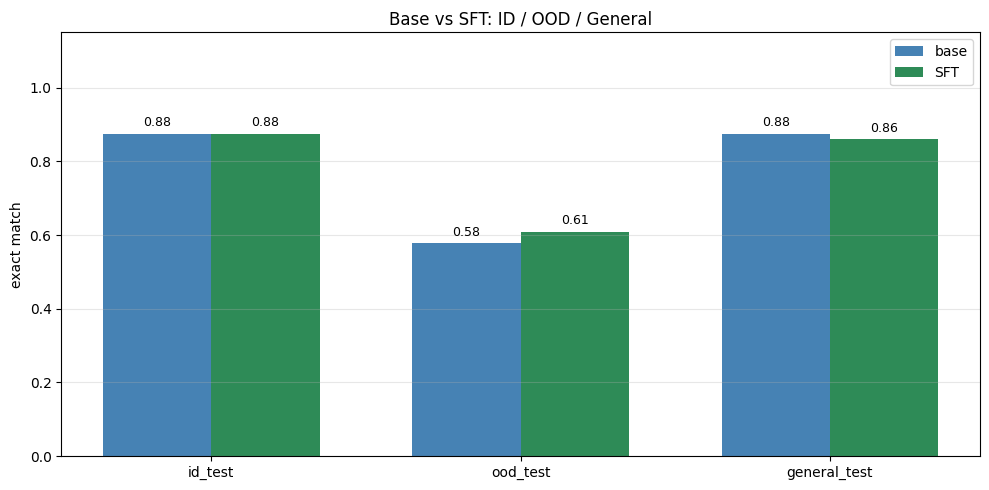

✔ Сохранено: /content/drive/MyDrive/lab9_artifacts/viz_summary.png
Артефакты: /content/drive/MyDrive/lab9_artifacts


In [12]:
# ============================================================
# ЯЧЕЙКА 15. ИТОГОВАЯ СВОДКА
# ============================================================
import matplotlib.pyplot as plt
splits_ordered = ["id_test", "ood_test", "general_test"]
base_vals = [evaluation[s]["exact_match_base"] for s in splits_ordered]
sft_vals = [evaluation[s]["exact_match_sft"] for s in splits_ordered]
x = np.arange(len(splits_ordered))
w = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w/2, base_vals, w, label="base", color="steelblue")
ax.bar(x + w/2, sft_vals, w, label="SFT", color="seagreen")
for i, (b, s) in enumerate(zip(base_vals, sft_vals)):
    ax.text(i - w/2, b + 0.02, f"{b:.2f}", ha="center", fontsize=9)
    ax.text(i + w/2, s + 0.02, f"{s:.2f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(splits_ordered)
ax.set_ylim(0, 1.15)
ax.set_ylabel("exact match")
ax.set_title("Base vs SFT: ID / OOD / General")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_summary.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_summary.png'}")
print(f"Артефакты: {ARTIFACTS}")

# Анализ результатов

Эксперимент проверял, даёт ли QLoRA-дообучение Qwen2.5-VL-3B-Instruct на 512 примерах ScienceQA прирост качества на трёх независимых срезах по 64 примера: ID (естественные науки, 1–6 классы), OOD (естественные науки, 7–12 классы) и General (другие предметы). Базовая модель показала 87.5% на ID, 57.8% на OOD и 87.5% на General; после SFT — 87.5% на ID (Δ=0.000), 60.9% на OOD (Δ=+3.1 п.п.) и 85.9% на General (Δ=−1.6 п.п.). Ни одна дельта не является статистически значимой: при $n=64$ погрешность Exact Match составляет около ±6 п.п., поэтому изменения в пределах 3 п.п. неотличимы от шума.

На ID-срезе прирост отсутствует, и это ожидаемо: базовая модель уже отвечает правильно на 56 из 64 вопросов, то есть близка к потолку, и SFT на малой выборке физически не может дать значимого улучшения. Важно, что адаптер при этом не ухудшил результат — он не сломал то, что работало. Дополнительный фактор — обнаруженный при визуальном аудите дисбаланс ответов: варианты A и B покрывают большинство правильных ответов, и тривиальная стратегия «всегда отвечать B» даёт заметную долю точности без понимания задачи. Это ограничение протокола, которое нужно честно указать: высокое качество на ID частично объясняется статистикой распределения, а не пониманием.

На OOD-срезе наблюдается единственный положительный эффект — плюс два правильных ответа из 64. Это согласуется с гипотезой о том, что SFT учит формату, а не знаниям: на более сложных вопросах базовая модель чаще сбивается с требуемого формата, начиная рассуждать вместо выдачи одной буквы, а адаптер эти ошибки формата исправляет. Прирост в пределах погрешности, но направление эффекта соответствует теоретическому ожиданию, что делает его содержательно значимым. На General-срезе значимой деградации не обнаружено — минус один пример из 64, — что указывает на отсутствие катастрофического забывания, но и улучшения переноса не произошло, как и ожидалось для домена, не представленного в обучении.

Бонусная гипотеза о том, что SFT улучшает ID, но ухудшает OOD из-за переобучения под домен, не подтвердилась: Δ на ID оказался нулевым, а Δ на OOD — положительным. Это означает, что в данном эксперименте SFT не привёл к переобучению под обучающее распределение в ущерб сложным срезам; напротив, единственный содержательный эффект адаптера проявился именно там, где базовая модель была слабее. Кривые обучения подтверждают корректность эксперимента: train loss снизился с 0.21 до 0.07, eval loss стабилизировался около 0.11 без признаков расхождения, лучший чекпоинт сохранён на финальном шаге — переобучения на валидации не было.

Результаты следует интерпретировать с учётом ограничений: малая тестовая выборка даёт погрешность порядка ±6 п.п., один запуск не позволяет оценить вариативность, дисбаланс ответов завышает абсолютные значения метрики на ID, а определение OOD как «естественные науки, 7–12 классы» является операциональным выбором границы. Главный содержательный вывод состоит не в том, что SFT не работает, а в том, что при сильной базовой модели и малой обучающей выборке потолок качества достигается без дообучения, и SFT оказывается инструментом приведения поведения модели к требуемому формату, а не инструментом улучшения знаний. Единственный срез, где этот эффект проявился, — OOD, где базовая модель чаще нарушала формат. Основной результат лабораторной — не абсолютные цифры прироста, а корректно проведённый полный цикл адаптации VLM с честной интерпретацией результатов и анализом ограничений протокола.

# Общий вывод

Эксперимент показал, что QLoRA-дообучение Qwen2.5-VL-3B-Instruct на 512 примерах ScienceQA за 60 шагов не даёт статистически значимого улучшения ни на одном из трёх срезов. На ID-срезе прирост отсутствует, поскольку базовая модель уже близка к потолку (87.5%), а дисбаланс ответов дополнительно завышает этот потолок. На OOD-срезе наблюдается небольшой положительный эффект (+3.1 п.п.), согласующийся с гипотезой о том, что SFT корректирует формат ответа, а не добавляет знаний; однако при $n=64$ этот эффект неотличим от шума. На General-срезе значимой деградации не обнаружено, что указывает на отсутствие катастрофического забывания, но и улучшения переноса не произошло, как и ожидалось для домена, не представленного в обучении.

Главный содержательный вывод состоит не в том, что SFT не работает, а в том, что при сильной базовой модели и малой обучающей выборке потолок качества достигается без дообучения, и SFT оказывается инструментом приведения поведения модели к требуемому формату, а не инструментом улучшения знаний. Единственный срез, где этот эффект проявился, — OOD, где базовая модель чаще нарушала формат. Это соответствует теоретическому пониманию SFT как обучения поведению, а не знаниям, и подтверждает, что для реального улучшения предметного качества требуются либо существенно большая выборка, либо более сложная задача, где базовая модель далека от потолка.

С практической точки зрения работа демонстрирует полный корректный цикл адаптации VLM при ограниченных ресурсах: подготовку данных с независимыми разбиениями, конфигурацию QLoRA, обучение через LLaMA-Factory, детерминированный инференс и сравнение базовой модели с адаптером на трёх срезах с анализом ошибок и ограничений. Именно этот цикл, а не абсолютные цифры прироста, является основным результатом лабораторной: он показывает, как корректно измерить эффект дообучения, как отличить реальное улучшение от артефакта протокола и как интерпретировать результаты с учётом дисбаланса данных, малой выборки и природы SFT.

In [1]:
from IPython.display import Image, display


In [4]:
import os
print("CWD:", os.getcwd())
print(os.listdir("."))

CWD: c:\Users\User\Desktop\ml_labs\SOTA_labs\lab9
['data', 'lab9_artifacts', 'Strelchenko_A_A_lab9.ipynb']


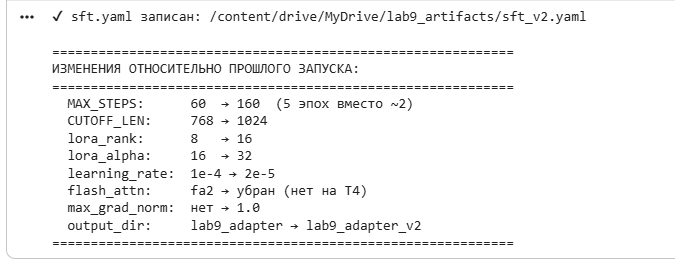

In [5]:
from PIL import Image
from IPython.display import display

display(Image.open("data/1.png").convert("RGB"))

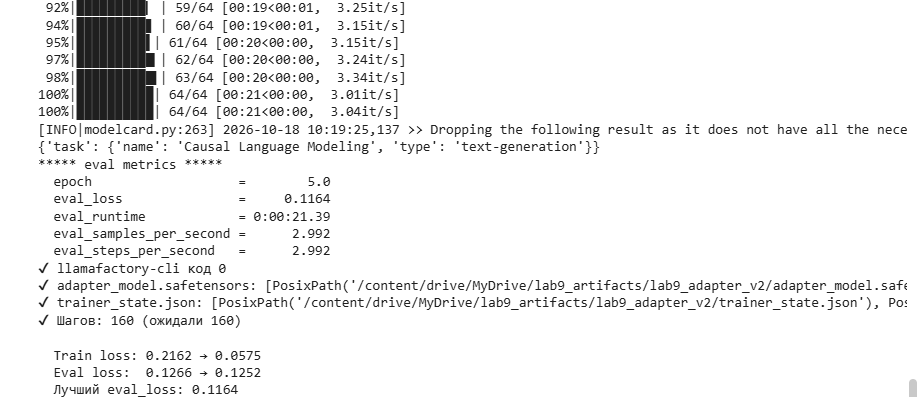

In [6]:
display(Image.open("data/2.png").convert("RGB"))

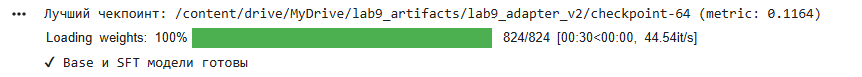

In [7]:
display(Image.open("data/3.png").convert("RGB"))

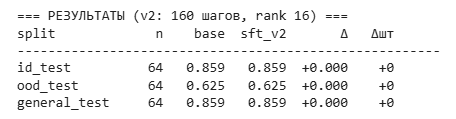

In [8]:
display(Image.open("data/4.png").convert("RGB"))

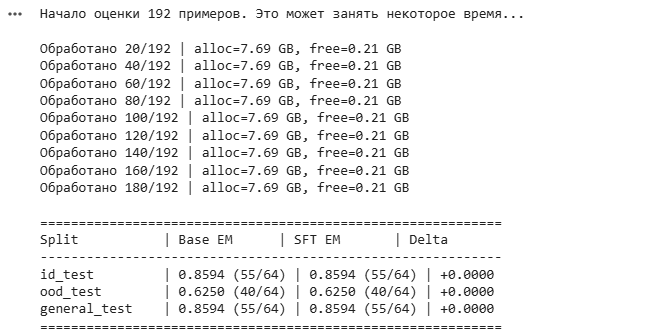

In [9]:
display(Image.open("data/5.png").convert("RGB"))